In [31]:

# ============================================================
# سلول تنظیمات — یک‌بار در ابتدای نوت‌بوک اجرا کنید
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

# تنظیمات نمایش
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)
plt.rcParams['figure.dpi'] = 100


In [32]:



# ---------- مسیرها ----------
ROOT = Path.cwd()
while ROOT.name and not (ROOT / ".git").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "raw" / "alzheimer"

uds = pd.read_csv(DATA_DIR / "udslong_imputed.csv")
mri = pd.read_csv(DATA_DIR / "mriscanclean.csv")

# ---------- انتخاب ستون‌های موردنیاز ----------
uds_cols = ["NACCID", "NACCUDSD", "NACCAGE", "CDRSUM"]
mri_cols = ["NACCID", "LH_ENTORHINAL_GVOL"]

uds_sub = uds[[c for c in uds_cols if c in uds.columns]].copy()
mri_sub = mri[[c for c in mri_cols if c in mri.columns]].copy()

df = uds_sub.merge(mri_sub, on="NACCID", how="inner", validate="one_to_one")
print("Merged shape:", df.shape)

# ---------- تمیزکاری کدهای ویژه ----------
special_codes = [8, 9, 88, 99, 888, 999, 9999]
df_clean = df.copy()
for col in ["NACCUDSD", "NACCAGE", "CDRSUM"]:
    df_clean[col] = df_clean[col].replace(special_codes, np.nan)

# ---------- رویداد A ----------
df_clean["A"] = df_clean["NACCUDSD"].isin([2, 3, 4])
n_A = df_clean["A"].sum()
print(f"\nP(A) = {n_A}/{len(df_clean)} = {n_A/len(df_clean):.3f}")

# ---------- رویداد B ----------
df_clean["B"] = df_clean["CDRSUM"] >= 1
n_B = df_clean["B"].sum()
print(f"P(B) = {n_B}/{len(df_clean)} = {n_B/len(df_clean):.3f}")

# ---------- متغیر تصادفی X ----------
X = df_clean["NACCAGE"].dropna()
print(f"\nX = NACCAGE: mean={X.mean():.2f}, std={X.std():.2f}, "
      f"min={X.min()}, max={X.max()}, n={len(X)}")

Merged shape: (1237, 5)

P(A) = 390/1237 = 0.315
P(B) = 322/1237 = 0.260

X = NACCAGE: mean=68.19, std=8.04, min=41.0, max=91.0, n=1237


In [33]:


# ---------- جدول توافقی 2×2 ----------
ct = pd.crosstab(df_clean["A"], df_clean["B"],
                 rownames=["A (اختلال شناختی)"],
                 colnames=["B (علائم زوال عقل)"],
                 margins=True, margins_name="مجموع")
print("جدول توافقی:")
print(ct)

# ---------- احتمال‌های حاشیه‌ای ----------
n      = len(df_clean)
n_A    = df_clean["A"].sum()
n_notA = n - n_A
n_B    = df_clean["B"].sum()
n_notB = n - n_B

p_A    = n_A / n
p_notA = n_notA / n
p_B    = n_B / n
p_notB = n_notB / n

print(f"\nP(A)   = {n_A}/{n}    = {p_A:.4f}")
print(f"P(Aᶜ)  = {n_notA}/{n} = {p_notA:.4f}")
print(f"P(B)   = {n_B}/{n}    = {p_B:.4f}")
print(f"P(Bᶜ)  = {n_notB}/{n} = {p_notB:.4f}")

# ---------- احتمال‌های مشترک (چهار خانه) ----------
n_AB     = ( df_clean["A"] &  df_clean["B"]).sum()
n_A_notB = ( df_clean["A"] & ~df_clean["B"]).sum()
n_notA_B = (~df_clean["A"] &  df_clean["B"]).sum()
n_notAB  = (~df_clean["A"] & ~df_clean["B"]).sum()

p_AB     = n_AB     / n
p_A_notB = n_A_notB / n
p_notA_B = n_notA_B / n
p_notAB  = n_notAB  / n

print(f"\nP(A ∩ B)     = {n_AB}/{n}     = {p_AB:.4f}")
print(f"P(A ∩ Bᶜ)    = {n_A_notB}/{n} = {p_A_notB:.4f}")
print(f"P(Aᶜ ∩ B)    = {n_notA_B}/{n} = {p_notA_B:.4f}")
print(f"P(Aᶜ ∩ Bᶜ)   = {n_notAB}/{n}  = {p_notAB:.4f}")

# ---------- بررسی مجموع = 1 ----------
print(f"\nبررسی: P(A)+P(Aᶜ) = {p_A + p_notA:.4f}")
print(f"بررسی: P(B)+P(Bᶜ) = {p_B + p_notB:.4f}")
print(f"بررسی: مجموع چهار خانه = {p_AB + p_A_notB + p_notA_B + p_notAB:.4f}")

# ---------- مقایسه با استقلال ----------
print(f"\nP(A)·P(B) = {p_A*p_B:.4f}  در مقابل  P(A∩B) = {p_AB:.4f}")
print(f"نسبت = {p_AB/(p_A*p_B):.4f}")

جدول توافقی:
B (علائم زوال عقل)  False  True  مجموع
A (اختلال شناختی)                     
False                 811    36    847
True                  104   286    390
مجموع                 915   322   1237

P(A)   = 390/1237    = 0.3153
P(Aᶜ)  = 847/1237 = 0.6847
P(B)   = 322/1237    = 0.2603
P(Bᶜ)  = 915/1237 = 0.7397

P(A ∩ B)     = 286/1237     = 0.2312
P(A ∩ Bᶜ)    = 104/1237 = 0.0841
P(Aᶜ ∩ B)    = 36/1237 = 0.0291
P(Aᶜ ∩ Bᶜ)   = 811/1237  = 0.6556

بررسی: P(A)+P(Aᶜ) = 1.0000
بررسی: P(B)+P(Bᶜ) = 1.0000
بررسی: مجموع چهار خانه = 1.0000

P(A)·P(B) = 0.0821  در مقابل  P(A∩B) = 0.2312
نسبت = 2.8172


In [34]:


# ---------- شمارش‌های پایه ----------
n     = len(df_clean)
n_A   = ( df_clean["A"]).sum()
n_notA= (~df_clean["A"]).sum()
n_B   = ( df_clean["B"]).sum()
n_notB= (~df_clean["B"]).sum()
n_AB  = ( df_clean["A"] &  df_clean["B"]).sum()
n_A_notB = ( df_clean["A"] & ~df_clean["B"]).sum()
n_notA_B = (~df_clean["A"] &  df_clean["B"]).sum()
n_notAB  = (~df_clean["A"] & ~df_clean["B"]).sum()

# ---------- احتمال‌های شرطی ----------
p_B_given_A    = n_AB / n_A
p_B_given_notA = n_notA_B / n_notA
p_A_given_B    = n_AB / n_B
p_A_given_notB = n_A_notB / n_notB

print("=== احتمال شرطی B به شرط A ===")
print(f"P(B | A)   = {n_AB}/{n_A}   = {p_B_given_A:.4f}")
print(f"P(B | Aᶜ)  = {n_notA_B}/{n_notA} = {p_B_given_notA:.4f}")
print(f"تغییر: {p_B_given_A - p_B_given_notA:+.4f}")
print(f"نسبت: P(B|A) / P(B|Aᶜ) = {p_B_given_A / p_B_given_notA:.2f}")

print("\n=== احتمال شرطی A به شرط B ===")
print(f"P(A | B)   = {n_AB}/{n_B}   = {p_A_given_B:.4f}")
print(f"P(A | Bᶜ)  = {n_A_notB}/{n_notB} = {p_A_given_notB:.4f}")
print(f"تغییر: {p_A_given_B - p_A_given_notB:+.4f}")
print(f"نسبت: P(A|B) / P(A|Bᶜ) = {p_A_given_B / p_A_given_notB:.2f}")

# ---------- مقایسه با حاشیه‌ای ----------
p_B = n_B / n
p_A = n_A / n
print("\n=== مقایسه با حاشیه‌ای ===")
print(f"P(B) = {p_B:.4f}")
print(f"P(B | A) - P(B)    = {p_B_given_A - p_B:+.4f}")
print(f"P(B | Aᶜ) - P(B)   = {p_B_given_notA - p_B:+.4f}")
print(f"\nP(A) = {p_A:.4f}")
print(f"P(A | B) - P(A)    = {p_A_given_B - p_A:+.4f}")
print(f"P(A | Bᶜ) - P(A)   = {p_A_given_notB - p_A:+.4f}")

=== احتمال شرطی B به شرط A ===
P(B | A)   = 286/390   = 0.7333
P(B | Aᶜ)  = 36/847 = 0.0425
تغییر: +0.6908
نسبت: P(B|A) / P(B|Aᶜ) = 17.25

=== احتمال شرطی A به شرط B ===
P(A | B)   = 286/322   = 0.8882
P(A | Bᶜ)  = 104/915 = 0.1137
تغییر: +0.7745
نسبت: P(A|B) / P(A|Bᶜ) = 7.81

=== مقایسه با حاشیه‌ای ===
P(B) = 0.2603
P(B | A) - P(B)    = +0.4730
P(B | Aᶜ) - P(B)   = -0.2178

P(A) = 0.3153
P(A | B) - P(A)    = +0.5729
P(A | Bᶜ) - P(A)   = -0.2016


In [35]:


n     = len(df_clean)
n_A   = ( df_clean["A"]).sum()
n_notA= (~df_clean["A"]).sum()
n_B   = ( df_clean["B"]).sum()
n_notB= (~df_clean["B"]).sum()
n_AB  = ( df_clean["A"] &  df_clean["B"]).sum()
n_A_notB = ( df_clean["A"] & ~df_clean["B"]).sum()
n_notA_B = (~df_clean["A"] &  df_clean["B"]).sum()
n_notAB  = (~df_clean["A"] & ~df_clean["B"]).sum()

# ---------- احتمال‌های مشاهده‌شده ----------
p_A   = n_A / n
p_B   = n_B / n
p_AB  = n_AB / n
p_A_notB = n_A_notB / n
p_notA_B = n_notA_B / n
p_notAB  = n_notAB / n

# ---------- احتمال‌های مورد انتظار تحت استقلال ----------
# اگر A و B مستقل بودند، هر خانه = n * P(A یا A^c) * P(B یا B^c)
exp_AB    = n * p_A * p_B
exp_A_notB= n * p_A * (1 - p_B)
exp_notA_B= n * (1 - p_A) * p_B
exp_notAB = n * (1 - p_A) * (1 - p_B)

print("=== فراوانی مشاهده‌شده در برابر مورد انتظار تحت استقلال ===")
print(f"{'خانه':<12} {'مشاهده':>8} {'انتظار':>10} {'تفاوت':>10} {'نسبت':>8}")
print("-" * 55)
for name, obs, exp in [
    ("A ∩ B",    n_AB,     exp_AB),
    ("A ∩ Bᶜ",   n_A_notB, exp_A_notB),
    ("Aᶜ ∩ B",   n_notA_B, exp_notA_B),
    ("Aᶜ ∩ Bᶜ",  n_notAB,  exp_notAB),
]:
    print(f"{name:<12} {obs:>8} {exp:>10.1f} {obs-exp:>+10.1f} {obs/exp:>8.2f}")

# ---------- بررسی استقلال با سه معیار ----------
print("\n=== معیار ۱: P(A ∩ B) در برابر P(A)·P(B) ===")
print(f"P(A)·P(B) = {p_A*p_B:.4f}")
print(f"P(A∩B)    = {p_AB:.4f}")
print(f"تفاوت     = {p_AB - p_A*p_B:+.4f}")
print(f"نسبت      = {p_AB/(p_A*p_B):.4f}")

print("\n=== معیار ۲: P(B | A) در برابر P(B) ===")
p_B_given_A    = n_AB / n_A
p_B_given_notA = n_notA_B / n_notA
print(f"P(B)       = {p_B:.4f}")
print(f"P(B | A)   = {p_B_given_A:.4f}")
print(f"P(B | Aᶜ)  = {p_B_given_notA:.4f}")
print(f"تفاوت P(B|A) - P(B)  = {p_B_given_A - p_B:+.4f}")
print(f"تفاوت P(B|Aᶜ) - P(B) = {p_B_given_notA - p_B:+.4f}")

print("\n=== معیار ۳: نسبت شانس (Odds Ratio) ===")
# OR = (n_AB * n_notAB) / (n_A_notB * n_notA_B)
OR = (n_AB * n_notAB) / (n_A_notB * n_notA_B)
print(f"OR = (n_AB · n_{'AᶜBᶜ'}) / (n_{'ABᶜ'} · n_{'AᶜB'})")
print(f"OR = ({n_AB} · {n_notAB}) / ({n_A_notB} · {n_notA_B})")
print(f"OR = {OR:.2f}")
print("→ OR = 1 یعنی استقلال؛ OR > 1 یعنی وابستگی مثبت")

# ---------- نتیجه‌گیری ----------
print("\n=== نتیجه‌گیری ===")
if abs(p_AB/(p_A*p_B) - 1) < 0.1 and abs(OR - 1) < 0.1:
    print("داده با فرض استقلال سازگار است.")
else:
    print("داده با فرض استقلال سازگار نیست؛ وابستگی مثبت قوی وجود دارد.")

=== فراوانی مشاهده‌شده در برابر مورد انتظار تحت استقلال ===
خانه           مشاهده     انتظار      تفاوت     نسبت
-------------------------------------------------------
A ∩ B             286      101.5     +184.5     2.82
A ∩ Bᶜ            104      288.5     -184.5     0.36
Aᶜ ∩ B             36      220.5     -184.5     0.16
Aᶜ ∩ Bᶜ           811      626.5     +184.5     1.29

=== معیار ۱: P(A ∩ B) در برابر P(A)·P(B) ===
P(A)·P(B) = 0.0821
P(A∩B)    = 0.2312
تفاوت     = +0.1491
نسبت      = 2.8172

=== معیار ۲: P(B | A) در برابر P(B) ===
P(B)       = 0.2603
P(B | A)   = 0.7333
P(B | Aᶜ)  = 0.0425
تفاوت P(B|A) - P(B)  = +0.4730
تفاوت P(B|Aᶜ) - P(B) = -0.2178

=== معیار ۳: نسبت شانس (Odds Ratio) ===
OR = (n_AB · n_AᶜBᶜ) / (n_ABᶜ · n_AᶜB)
OR = (286 · 811) / (104 · 36)
OR = 61.95
→ OR = 1 یعنی استقلال؛ OR > 1 یعنی وابستگی مثبت

=== نتیجه‌گیری ===
داده با فرض استقلال سازگار نیست؛ وابستگی مثبت قوی وجود دارد.


In [36]:

ROOT = Path.cwd()
while ROOT.name and not (ROOT / ".git").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "raw" / "alzheimer"

uds = pd.read_csv(DATA_DIR / "udslong_imputed.csv")
mri = pd.read_csv(DATA_DIR / "mriscanclean.csv")

# ---------- ستون‌های بیشتر برای df_clean2 ----------
uds_cols2 = ["NACCID", "NACCUDSD", "NACCAGE", "SEX", "EDUC", "CDRSUM", "NACCGDS"]
mri_cols2 = ["NACCID", "LH_ENTORHINAL_GVOL", "LH_ENTORHINAL_AVGTH",
             "LH_PARAHIPPOCAMPAL_GVOL", "RH_PARAHIPPOCAMPAL_GVOL"]

uds_sub2 = uds[[c for c in uds_cols2 if c in uds.columns]].copy()
mri_sub2 = mri[[c for c in mri_cols2 if c in mri.columns]].copy()

df_clean2 = uds_sub2.merge(mri_sub2, on="NACCID", how="inner", validate="one_to_one")
print("df_clean2 shape:", df_clean2.shape)
print("Columns:", df_clean2.columns.tolist())

# ---------- تمیزکاری کدهای ویژه ----------
special_codes = [8, 9, 88, 99, 888, 999, 9999]
for col in ["NACCUDSD", "NACCAGE", "CDRSUM", "SEX", "EDUC", "NACCGDS"]:
    if col in df_clean2.columns:
        df_clean2[col] = df_clean2[col].replace(special_codes, np.nan)

# ---------- رویدادهای A و B (برای سازگاری با تحلیل‌های قبلی) ----------
df_clean2["A"] = df_clean2["NACCUDSD"].isin([2, 3, 4])
df_clean2["B"] = df_clean2["CDRSUM"] >= 1

print("\nتوزیع SEX:")
print(df_clean2["SEX"].value_counts(dropna=False).sort_index())
print("\nتوزیع EDUC (۱۰ مقدار اول):")
print(df_clean2["EDUC"].value_counts(dropna=False).sort_index().head(10))

df_clean2 shape: (1237, 11)
Columns: ['NACCID', 'NACCUDSD', 'NACCAGE', 'SEX', 'EDUC', 'CDRSUM', 'NACCGDS', 'LH_ENTORHINAL_GVOL', 'LH_ENTORHINAL_AVGTH', 'LH_PARAHIPPOCAMPAL_GVOL', 'RH_PARAHIPPOCAMPAL_GVOL']

توزیع SEX:
SEX
1.0    497
2.0    740
Name: count, dtype: int64

توزیع EDUC (۱۰ مقدار اول):
EDUC
0.0       1
1.0       2
2.0       2
6.0       3
7.0       1
10.0      2
11.0      2
12.0    118
13.0     55
14.0    136
Name: count, dtype: int64


=== متغیر دودویی X = زن بودن ===
n = 1237
X = 1 (زن):  740
X = 0 (مرد): 497
p̂ = 0.5982

=== فرض ۱: دو پیامد ===
توزیع SEX: {2.0: 740, 1.0: 497}
→ SEX فقط دو مقدار ۱ (مرد) و ۲ (زن) دارد. فرض ۱ برقرار است.

=== فرض ۲: p ثابت در سراسر نمونه ===

p̂ (نسبت زنان) در زیرگروه‌های سنی:
  سن < 60        n= 173, p̂ = 0.6763
  60 ≤ سن < 70   n= 512, p̂ = 0.6250
  70 ≤ سن < 80   n= 454, p̂ = 0.5463
  سن ≥ 80        n=  98, p̂ = 0.5612

p̂ (نسبت زنان) در زیرگروه‌های شناختی:
  سالم (NACCUDSD=1)            n= 847, p̂ = 0.6434
  اختلال (NACCUDSD∈{2,3,4})    n= 390, p̂ = 0.5000

p̂ (نسبت زنان) در زیرگروه‌های تحصیلات:
  EDUC < 12      n=  13, p̂ = 0.7692
  12 ≤ EDUC < 16 n= 333, p̂ = 0.6907
  EDUC ≥ 16      n= 885, p̂ = 0.5638

=== فرض ۳: استقلال ===
هر مشاهده یک فرد مستقل است (NACCID یکتا).
→ استقلال در سطح مشاهده برقرار است؛
اما نمونه‌گیری چندمرکزی ممکن است وابستگی خوشه‌ای ایجاد کند.
در این پروژه، ساختار خوشه‌ای در داده موجود نیست.

=== Bootstrap (1000 نمونه 50 نفره) ===
میانگین تجربی: 30.12
انحراف مع

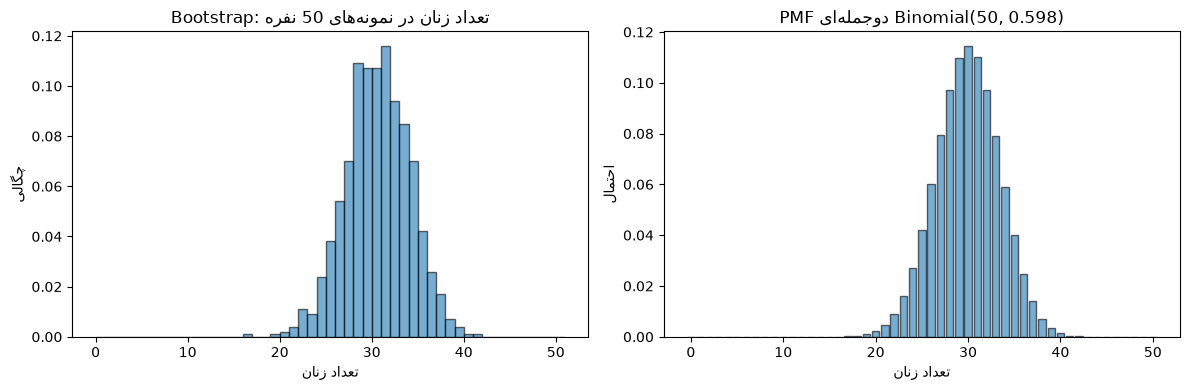

In [37]:

import matplotlib.pyplot as plt

# ============================================================
# متغیر دودویی: X = «آیا فرد زن است؟» (SEX = 2 → زن، SEX = 1 → مرد)
# ============================================================
df_clean2["X_female"] = (df_clean2["SEX"] == 2).astype(int)
# نکته: مقادیر NaN در SEX به 0 تبدیل می‌شوند؛ ابتدا NaN را حذف کنید
df_clean2 = df_clean2.dropna(subset=["SEX", "NACCAGE"]).copy()
df_clean2["X_female"] = (df_clean2["SEX"] == 2).astype(int)

n = len(df_clean2)
p_hat = df_clean2["X_female"].mean()

print("=== متغیر دودویی X = زن بودن ===")
print(f"n = {n}")
print(f"X = 1 (زن):  {df_clean2['X_female'].sum()}")
print(f"X = 0 (مرد): {(df_clean2['X_female'] == 0).sum()}")
print(f"p̂ = {p_hat:.4f}")

# ============================================================
# فرض ۱: دو پیامد
# ============================================================
print("\n=== فرض ۱: دو پیامد ===")
print("توزیع SEX:", df_clean2["SEX"].value_counts().to_dict())
print("→ SEX فقط دو مقدار ۱ (مرد) و ۲ (زن) دارد. فرض ۱ برقرار است.")

# ============================================================
# فرض ۲: p ثابت در سراسر نمونه
# ============================================================
print("\n=== فرض ۲: p ثابت در سراسر نمونه ===")
print("\np̂ (نسبت زنان) در زیرگروه‌های سنی:")
for label, mask in [
    ("سن < 60", df_clean2["NACCAGE"] < 60),
    ("60 ≤ سن < 70", (df_clean2["NACCAGE"] >= 60) & (df_clean2["NACCAGE"] < 70)),
    ("70 ≤ سن < 80", (df_clean2["NACCAGE"] >= 70) & (df_clean2["NACCAGE"] < 80)),
    ("سن ≥ 80", df_clean2["NACCAGE"] >= 80),
]:
    sub = df_clean2[mask]
    if len(sub) > 0:
        print(f"  {label:<14} n={len(sub):>4}, p̂ = {sub['X_female'].mean():.4f}")

print("\np̂ (نسبت زنان) در زیرگروه‌های شناختی:")
for label, mask in [
    ("سالم (NACCUDSD=1)", df_clean2["NACCUDSD"] == 1),
    ("اختلال (NACCUDSD∈{2,3,4})", df_clean2["NACCUDSD"].isin([2, 3, 4])),
]:
    sub = df_clean2[mask]
    if len(sub) > 0:
        print(f"  {label:<28} n={len(sub):>4}, p̂ = {sub['X_female'].mean():.4f}")

print("\np̂ (نسبت زنان) در زیرگروه‌های تحصیلات:")
for label, mask in [
    ("EDUC < 12", df_clean2["EDUC"] < 12),
    ("12 ≤ EDUC < 16", (df_clean2["EDUC"] >= 12) & (df_clean2["EDUC"] < 16)),
    ("EDUC ≥ 16", df_clean2["EDUC"] >= 16),
]:
    sub = df_clean2[mask]
    if len(sub) > 0:
        print(f"  {label:<14} n={len(sub):>4}, p̂ = {sub['X_female'].mean():.4f}")

# ============================================================
# فرض ۳: استقلال
# ============================================================
print("\n=== فرض ۳: استقلال ===")
print("هر مشاهده یک فرد مستقل است (NACCID یکتا).")
print("→ استقلال در سطح مشاهده برقرار است؛")
print("اما نمونه‌گیری چندمرکزی ممکن است وابستگی خوشه‌ای ایجاد کند.")
print("در این پروژه، ساختار خوشه‌ای در داده موجود نیست.")

# ============================================================
# Bootstrap: توزیع تعداد زنان در نمونه‌های ۵۰ نفره
# ============================================================
np.random.seed(42)
sample_size = 50
n_boot = 1000
counts = []
for _ in range(n_boot):
    sample = df_clean2["X_female"].sample(sample_size, replace=True)
    counts.append(sample.sum())
counts = np.array(counts)

print(f"\n=== Bootstrap ({n_boot} نمونه {sample_size} نفره) ===")
print(f"میانگین تجربی: {counts.mean():.2f}")
print(f"انحراف معیار تجربی: {counts.std():.2f}")

binom = stats.binom(n=sample_size, p=p_hat)
print(f"\nBinomial({sample_size}, {p_hat:.3f}):")
print(f"  میانگین تئوریک: {binom.mean():.2f}")
print(f"  انحراف معیار تئوریک: {binom.std():.2f}")

# ============================================================
# شرایط تقریب نرمال
# ============================================================
print("\n=== شرایط تقریب نرمال ===")
print(f"np = {sample_size * p_hat:.2f}  (باید ≥ 5 باشد)")
print(f"n(1-p) = {sample_size * (1-p_hat):.2f}  (باید ≥ 5 باشد)")
if sample_size * p_hat >= 5 and sample_size * (1-p_hat) >= 5:
    print("→ شرایط تقریب نرمال برقرار است.")
else:
    print("→ شرایط تقریب نرمال برقرار نیست؛ دوجمله‌ای باید دقیق استفاده شود.")

# ============================================================
# نمودار
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(counts, bins=range(0, sample_size+2), density=True,
             alpha=0.6, edgecolor='black')
axes[0].set_title(f'Bootstrap: تعداد زنان در نمونه‌های {sample_size} نفره')
axes[0].set_xlabel('تعداد زنان')
axes[0].set_ylabel('چگالی')

x = np.arange(0, sample_size+1)
axes[1].bar(x, binom.pmf(x), alpha=0.6, edgecolor='black')
axes[1].set_title(f'PMF دوجمله‌ای Binomial({sample_size}, {p_hat:.3f})')
axes[1].set_xlabel('تعداد زنان')
axes[1].set_ylabel('احتمال')

plt.tight_layout()
plt.show()

=== آماره‌های توصیفی NACCAGE ===
n     = 1237
میانگین = 68.19
میانه   = 68.00
انحراف معیار = 8.04
چولگی  = -0.2520
کشیدگی = 0.1749
کمینه  = 41, بیشینه = 91

=== آزمون‌های نرمال بودن ===
Shapiro-Wilk:  W = 0.9940, p = 7.3141e-05
Kolmogorov-Smirnov: D = 0.0447, p = 1.3695e-02
D'Agostino-Pearson: statistic = 14.3492, p = 7.6578e-04


C:\Users\Parmidaa\AppData\Local\Temp\ipykernel_19448\2441048762.py:49: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, 0].boxplot(x, vert=False)


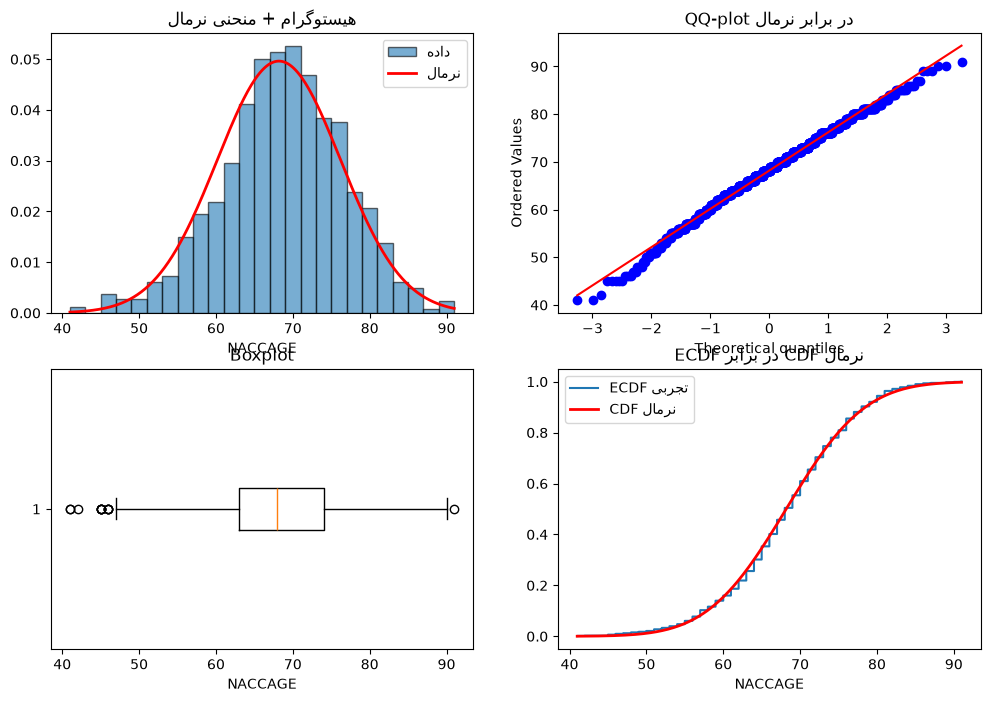

In [ ]:
x = df_clean["NACCAGE"].dropna()
n = len(x)

print("=== آماره‌های توصیفی NACCAGE ===")
print(f"n     = {n}")
print(f"میانگین = {x.mean():.2f}")
print(f"میانه   = {x.median():.2f}")
print(f"انحراف معیار = {x.std():.2f}")
print(f"چولگی  = {x.skew():.4f}")
print(f"کشیدگی = {x.kurtosis():.4f}")
print(f"کمینه  = {x.min():.0f}, بیشینه = {x.max():.0f}")

# ============================================================
# آزمون‌های نرمال بودن
# ============================================================
print("\n=== آزمون‌های نرمال بودن ===")
sw_stat, sw_p = stats.shapiro(x)
print(f"Shapiro-Wilk:  W = {sw_stat:.4f}, p = {sw_p:.4e}")

# --- KS با تابع CDF صریح (سازگار با همه نسخه‌ها) ---
mu, sigma = x.mean(), x.std(ddof=1)
ks_stat, ks_p = stats.kstest(x, stats.norm(mu, sigma).cdf)
print(f"Kolmogorov-Smirnov: D = {ks_stat:.4f}, p = {ks_p:.4e}")

# --- D'Agostino-Pearson ---
dag_stat, dag_p = stats.normaltest(x)
print(f"D'Agostino-Pearson: statistic = {dag_stat:.4f}, p = {dag_p:.4e}")

# ============================================================
# نمودارهای تشخیصی
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# ۱. هیستوگرام + منحنی نرمال
axes[0, 0].hist(x, bins=25, density=True, alpha=0.6,
                edgecolor='black', label='داده')
xs = np.linspace(x.min(), x.max(), 200)
axes[0, 0].plot(xs, stats.norm.pdf(xs, x.mean(), x.std()),
                'r-', lw=2, label='نرمال')
axes[0, 0].set_title('هیستوگرام + منحنی نرمال')
axes[0, 0].set_xlabel('NACCAGE')
axes[0, 0].legend()

# ۲. QQ-plot
stats.probplot(x, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('QQ-plot در برابر نرمال')

# ۳. Boxplot
axes[1, 0].boxplot(x, vert=False)
axes[1, 0].set_title('Boxplot')
axes[1, 0].set_xlabel('NACCAGE')

# ۴. ECDF در برابر CDF نرمال
xs_sorted = np.sort(x)
ecdf = np.arange(1, n+1) / n
axes[1, 1].step(xs_sorted, ecdf, where='post', label='ECDF تجربی')
axes[1, 1].plot(xs, stats.norm.cdf(xs, x.mean(), x.std()),
                'r-', lw=2, label='CDF نرمال')
axes[1, 1].set_title('ECDF در برابر CDF نرمال')
axes[1, 1].set_xlabel('NACCAGE')
axes[1, 1].legend()

ROOT = Path.cwd()
while ROOT.name and not (ROOT / ".git").exists():
    ROOT = ROOT.parent

FIGS_DIR = ROOT / "figures"
out_path = FIGS_DIR / "phase2_q6_normality.png"   # مسیر کامل
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
plt.show()